In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs("plots", exist_ok=True)
print("Libraries loaded successfully!")

Matplotlib is building the font cache; this may take a moment.


Libraries loaded successfully!


In [2]:
df = pd.read_csv("creditcard.csv")
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
print(df.shape)
print(df.info())
print(df.isnull().sum())

(284807, 31)
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     

In [4]:
print(df["Class"].value_counts())
print(df["Class"].value_counts(normalize=True) * 100)

Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


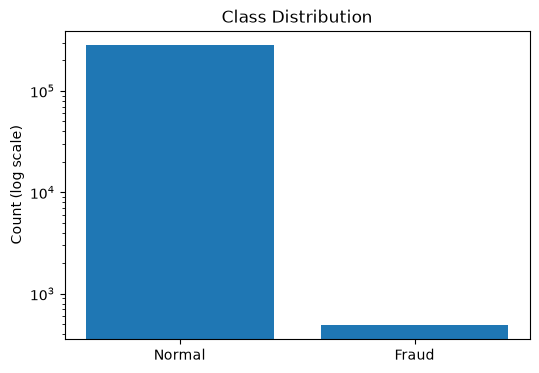

In [5]:
counts = df["Class"].value_counts()

plt.figure(figsize=(6,4))
plt.bar(["Normal", "Fraud"], counts.values)
plt.yscale("log")
plt.title("Class Distribution")
plt.ylabel("Count (log scale)")
plt.savefig("plots/class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [6]:
print(df["Amount"].describe())

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64


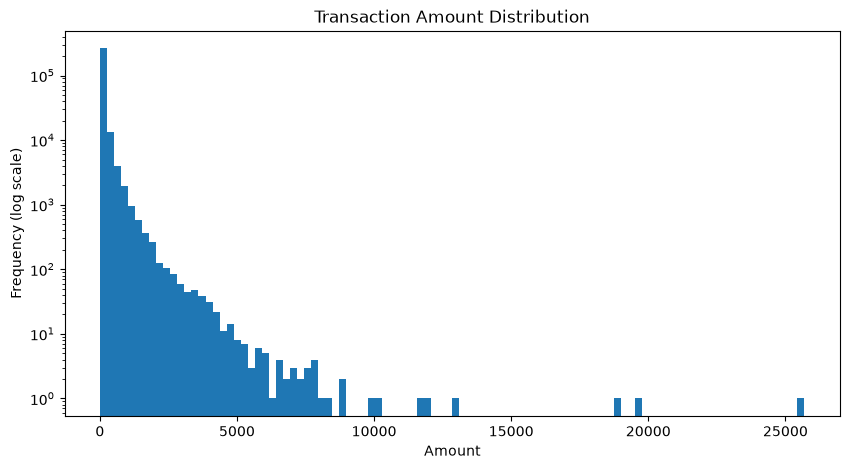

In [7]:
plt.figure(figsize=(10,5))
plt.hist(df["Amount"], bins=100)
plt.yscale("log")
plt.title("Transaction Amount Distribution")
plt.xlabel("Amount")
plt.ylabel("Frequency (log scale)")
plt.savefig("plots/amount_hist.png", dpi=300, bbox_inches="tight")
plt.show()

In [8]:
normal = df[df["Class"] == 0]["Amount"]
fraud = df[df["Class"] == 1]["Amount"]

plt.figure(figsize=(8,5))
plt.boxplot([normal, fraud], labels=["Normal", "Fraud"])
plt.yscale("log")
plt.title("Amount by Class")
plt.ylabel("Amount (log scale)")
plt.savefig("plots/amount_by_class.png", dpi=300, bbox_inches="tight")
plt.show()

TypeError: boxplot() got an unexpected keyword argument 'labels'. Did you mean 'label'?

<Figure size 800x500 with 0 Axes>

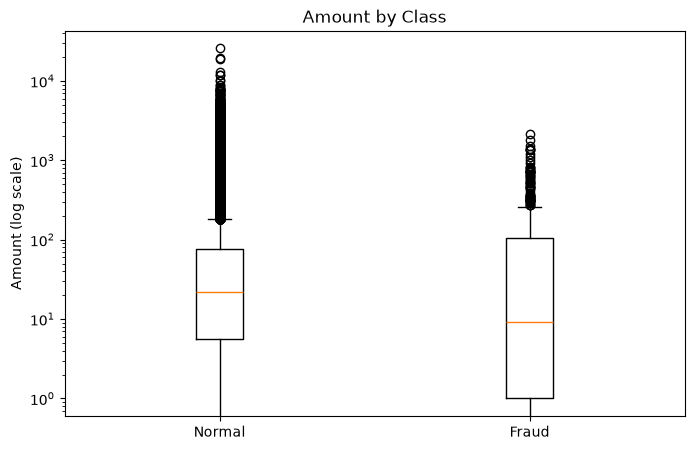

In [9]:
normal = df[df["Class"] == 0]["Amount"]
fraud = df[df["Class"] == 1]["Amount"]

plt.figure(figsize=(8,5))
plt.boxplot([normal, fraud], tick_labels=["Normal", "Fraud"])
plt.yscale("log")
plt.title("Amount by Class")
plt.ylabel("Amount (log scale)")
plt.savefig("plots/amount_by_class.png", dpi=300, bbox_inches="tight")
plt.show()

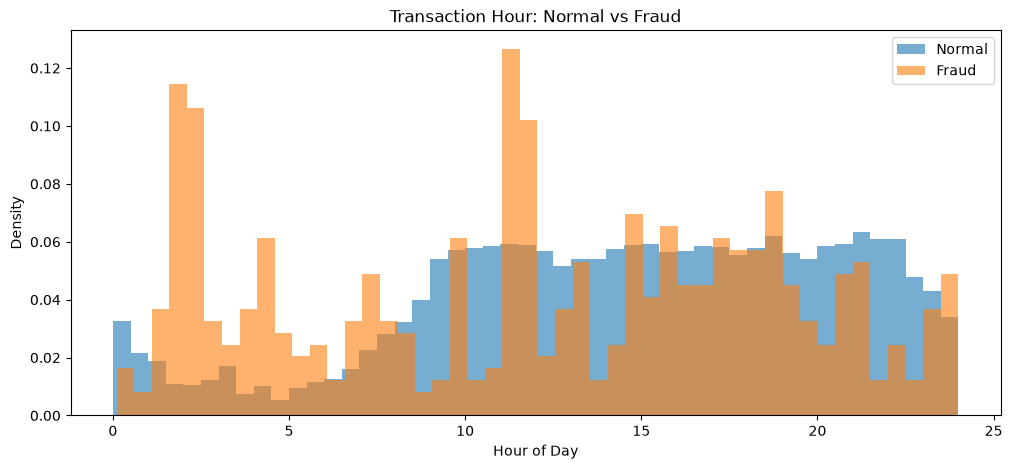

In [10]:
df["Hour"] = (df["Time"] / 3600) % 24

plt.figure(figsize=(12,5))
plt.hist(df[df["Class"] == 0]["Hour"], bins=48, alpha=0.6, label="Normal", density=True)
plt.hist(df[df["Class"] == 1]["Hour"], bins=48, alpha=0.6, label="Fraud", density=True)
plt.title("Transaction Hour: Normal vs Fraud")
plt.xlabel("Hour of Day")
plt.ylabel("Density")
plt.legend()
plt.savefig("plots/hour_by_class.png", dpi=300, bbox_inches="tight")
plt.show()

In [11]:
corr = df.corr()["Class"].sort_values(ascending=False)
print(corr)

Class     1.000000
V11       0.154876
V4        0.133447
V2        0.091289
V21       0.040413
V19       0.034783
V20       0.020090
V8        0.019875
V27       0.017580
V28       0.009536
Amount    0.005632
V26       0.004455
V25       0.003308
V22       0.000805
V23      -0.002685
V15      -0.004223
V13      -0.004570
V24      -0.007221
Time     -0.012323
Hour     -0.017082
V6       -0.043643
V5       -0.094974
V9       -0.097733
V1       -0.101347
V18      -0.111485
V7       -0.187257
V3       -0.192961
V16      -0.196539
V10      -0.216883
V12      -0.260593
V14      -0.302544
V17      -0.326481
Name: Class, dtype: float64


In [12]:
Q1 = df["Amount"].quantile(0.25)
Q3 = df["Amount"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df["Amount"] < lower) | (df["Amount"] > upper)]

print("Outliers:", len(outliers))
print("Frauds in outliers:", outliers["Class"].sum())
print("Total frauds:", df["Class"].sum())

Outliers: 31904
Frauds in outliers: 91
Total frauds: 492


# Key Findings

1. **Class Imbalance:** Fraud is extremely rare (0.172% of transactions).
2. **Amount Distribution:** Transaction amounts are highly right-skewed. Most transactions are small, with a few very large outliers.
3. **Amount vs Class:** Fraud amounts overlap heavily with normal amounts. Amount alone is not enough to detect fraud.
4. **Time Patterns:** Fraudulent activity spikes at odd hours (e.g., 2-3 AM), while normal transactions follow a human sleep/wake cycle.
5. **Correlation:** Specific PCA features (like V17, V14, V12) are strongly correlated with fraud and will be valuable for detection.
6. **Outliers:** There are 31,904 amount outliers, but only 91 are fraud. This confirms amount alone is insufficient.